In [ ]:
import mrcfile
from pathlib import Path

import torch
import numpy as np

import napari

import pandas as pd

from skimage.measure import marching_cubes
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import mmdf
from torch_calculate_electrostatic_potential import (
    GridConfig,
    default_sublattice_radius,
    potential_from_structure_3d,
)
from torch_structure_manipulation import AtomicStructure, center_structure
from torch_fourier_filter.dose_weight import dose_weight_2d
from torch_ctf import calculate_ctf_2d
from torch_grid_utils import fftfreq_grid
from torch_fourier_slice import (
    backproject_2d_to_3d,
    project_3d_to_2d,
)
from torch_affine_utils.transforms_3d import Ry


In [22]:
def compute_power_spectrum(data: np.ndarray) -> np.ndarray:
    ft = np.fft.fftshift(np.fft.fftn(data))
    return np.log(np.abs(ft) + 1e-8)  # small epsilon to avoid log(0)

def simulate_pdb(pdb_id: str, device: str = "cuda") -> torch.Tensor:
    """Download a PDB entry and simulate its potential in volts (cached on disk)."""
    CACHE.mkdir(parents=True, exist_ok=True)
    volume_path = CACHE / f"{pdb_id}_box{BOX}_{PIXEL_SPACING:g}apx_peng.pt"
    if volume_path.exists():
        return torch.load(volume_path)

    structure_path = CACHE / f"{pdb_id}.cif"
    if not structure_path.exists():
        print(f"downloading {pdb_id} from RCSB ...")
        response = urllib3.PoolManager().request(
            "GET", f"https://files.rcsb.org/download/{pdb_id}.cif"
        )
        if response.status != 200:
            raise RuntimeError(f"download of {pdb_id} failed: HTTP {response.status}")
        structure_path.write_bytes(response.data)

    print(f"simulating {pdb_id}: {BOX}^3 volume at {PIXEL_SPACING} A/px ...")
    atoms = center_structure(mmdf.read(str(structure_path)), zyx=False)
    structure = AtomicStructure.from_annotated_dataframe(atoms, device=device)
    grid_3d = GridConfig.from_grid_shape_and_voxel_size(
        grid_shape=(BOX, BOX, BOX),
        voxel_size=(PIXEL_SPACING,) * 3,
        center_zyx=(0.0, 0.0, 0.0),
        sublattice_radius=default_sublattice_radius(PIXEL_SPACING),
        device=torch.device(device),
    )
    volume = potential_from_structure_3d(
        structure, grid_3d,
        scattering_factors="peng_bonded", bonded_fallback="elemental",
    ).cpu()
    torch.save(volume, volume_path)
    return volume

## Visualize reconstructed tomograms

In [3]:
base_path = Path("C:/Users/ruben/OneDrive - Delft University of Technology/Documenten/Nanobiology 6/ARP/phantom_tomogram_13_10/")

refined_tomograms = {}
fourier_refined_tomograms = {}
no_noise_tomograms = {}
fourier_no_noise_tomograms = {}



for n in range(0,4):
    refined_tomopath = base_path / f"ddw/noisy_phantom_tomo_id{n}_even+noisy_phantom_tomo_id{n}_odd_refined.mrc"
    with mrcfile.open(refined_tomopath) as mrc:
        refined_tomogram_tensor = torch.tensor(mrc.data, dtype=torch.float32)
        refined_tomograms[n] = refined_tomogram_tensor
        fourier_refined_tomograms[n] = compute_power_spectrum(refined_tomogram_tensor)

    no_noise_tomopath = base_path / f"no_noise/no_noise_phantom_tomo_id{n}.mrc"
    with mrcfile.open(no_noise_tomopath) as mrc:
        no_noise_tomogram_tensor = torch.tensor(mrc.data, dtype=torch.float32)
        no_noise_tomograms[n] = no_noise_tomogram_tensor
        fourier_no_noise_tomograms[n] = compute_power_spectrum(no_noise_tomogram_tensor)


In [4]:
a = napari.Viewer()
for n in range(0,4):
    if n == 3:
        a.add_image(refined_tomograms[n], name=f"subtomo {n}")
        a.add_image(fourier_refined_tomograms[n], name=f"fourier ref {n}")
        a.add_image(no_noise_tomograms[n], name=f"No noise {n}")
        a.add_image(fourier_no_noise_tomograms[n], name=f"Fourier no noise {n}")


## Load ground truth proteins

In [ ]:
## load proteins
PDB_ID_ribosome = "4v6x"  # 80S ribosome
PDB_ID_cohesin = "6wg3"  # Cohesin complex
PIXEL_SPACING = 10.0 # angstroms per pixel -> Nyquist at 20.0 A
# VOLTAGE = 300  # in keV
BOX = 96  # 1280 A box
CACHE = Path.home() / ".cache" / "arp"


ribosome = np.array(simulate_pdb(PDB_ID_ribosome, device="cpu"))
cohesin = np.array(simulate_pdb(PDB_ID_cohesin, device="cpu"))

box_size = ribosome.shape[0]
center = box_size // 2

# Precompute squared distance grid
z, y, x = np.ogrid[:box_size, :box_size, :box_size]
dist_sq = (x - center)**2 + (y - center)**2 + (z - center)**2

last_active_radius = 0

for volume in [ribosome, cohesin]:
    for r in range(center + 1):
        if r == 0:
            shell_mask = (dist_sq == 0)
        else:
            lower_bound = (r - 0.5) ** 2
            upper_bound = (r + 0.5) ** 2
            shell_mask = (dist_sq >= lower_bound) & (dist_sq < upper_bound)
        
        # Check how much ribosome space exists in this specific shell
        ribosome_in_shell = np.sum(volume[shell_mask])
        
        if ribosome_in_shell > 0:
            last_active_radius = r
        else:
            # Once we hit an empty shell beyond the core, we can see if it stays empty
            # (Optional: break early if you are sure there's no hollow outer layers)
            pass

    print(f"The ribosome takes up no space starting from radius: {last_active_radius + 1}")
    print(f"So that means maximum diameter is {last_active_radius*2*10} Angstrom")


C:\Users\ruben\AppData\Local\Temp\ipykernel_8584\589380915.py:10: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ribosome = np.array(simulate_pdb(PDB_ID_ribosome, device="cpu"))
C:\Users\ruben\AppData\Local\Temp\ipykernel_8584\589380915.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cohesin = np.array(simulate_pdb(PDB_ID_cohesin, device="cpu"))


The ribosome takes up no space starting from radius: 26
So that means maximum diameter is 500 Angstrom
The ribosome takes up no space starting from radius: 15
So that means maximum diameter is 280 Angstrom


## Localize and analyze proteins

In [72]:
protein_data = pd.read_csv(base_path / "protein_data.csv")
protein_data.head(5)

r_rib, r_coh = 26, 15
ribosome_small = ribosome[center-r_rib:center+r_rib+1, center-r_rib:center+r_rib+1, center-r_rib:center+r_rib+1]
cohesin_small = cohesin[center-r_coh:center+r_coh+1, center-r_coh:center+r_coh+1, center-r_coh:center+r_coh+1]

In [ ]:
import re
def parse_loc(s):
    return [int(v) for v in re.findall(r"-?\d+", s.replace("np.int64", ""))]

from scipy.ndimage import affine_transform

def parse_rot(s):
    return np.array([float(v) for v in re.findall(r"-?\d+\.?\d*(?:e-?\d+)?", s)]).reshape(3, 3)

def unrotate(sub, R, zyx=True, center_offset_zyx=None):
    if zyx:                      # matrix given in (x,y,z); volume indexed (z,y,x)
        P = np.eye(3)[::-1]; R = P @ R @ P
    c = (np.array(sub.shape) - 1) / 2
    # affine_transform maps output->input coords, so passing R undoes the rotation R
    offset = c - R @ c
    if center_offset_zyx is not None:
        offset -= R @ center_offset_zyx
    return affine_transform(sub, R, offset=offset, order=1)

def ground_truth_center_offset_zyx(vol, threshold=0.05):
    v = vol.transpose(2, 1, 0)                     # frame used during placement (x, y, z)
    nz = np.argwhere(v >= threshold)
    p_center = (nz.min(0) + nz.max(0)) / 2         # rotation centre used in placement
    delta = p_center - (np.array(v.shape) - 1) / 2
    return delta[::-1]                              # to (z, y, x)

In [93]:
rib_center_offset_zyx = ground_truth_center_offset_zyx(ribosome)
rib_list = []

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "cohesin":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = refined_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 26
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        rib_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + rib_vol.shape[0],
            y_start:y_start + rib_vol.shape[1],
            x_start:x_start + rib_vol.shape[2],
        ]

        rib_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        rib_vol_unrot = unrotate(
            rib_vol,
            parse_rot(line["rotation"]),
            center_offset_zyx=rib_center_offset_zyx,
        )

        rib_list.append((i, rib_vol))

coh_list = []
coh_center_offset_zyx = ground_truth_center_offset_zyx(cohesin)

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "ribosome":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = refined_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 15
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        coh_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + coh_vol.shape[0],
            y_start:y_start + coh_vol.shape[1],
            x_start:x_start + coh_vol.shape[2],
        ]

        coh_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        coh_vol_unrot = unrotate(
            coh_vol,
            parse_rot(line["rotation"]),
            center_offset_zyx=coh_center_offset_zyx
        )

        coh_list.append((i, coh_vol))

ribosome 115 66 50
ribosome 38 210 35
ribosome 126 224 71
ribosome 142 187 73
ribosome 40 63 55
ribosome 158 37 72
ribosome 91 40 72
ribosome 228 34 46
ribosome 227 83 34
ribosome 82 208 58
ribosome 33 184 56
ribosome 54 155 53
ribosome 174 225 68
ribosome 110 157 30
ribosome 171 108 33
ribosome 136 130 44
ribosome 172 64 44
ribosome 93 125 70
ribosome 196 184 60
ribosome 74 85 26
ribosome 199 76 31
ribosome 155 165 35
ribosome 176 146 46
ribosome 142 108 31
ribosome 170 158 45
ribosome 110 177 72
ribosome 68 124 55
ribosome 86 47 32
ribosome 100 152 38
ribosome 208 205 59
ribosome 62 35 63
ribosome 114 78 65
ribosome 193 114 52
ribosome 171 229 33
ribosome 222 146 51
ribosome 135 136 55
ribosome 34 135 42
ribosome 215 63 38
ribosome 167 131 35
ribosome 81 166 55
ribosome 36 209 37
ribosome 86 107 57
ribosome 154 107 70
ribosome 208 90 50
ribosome 107 163 70
ribosome 41 107 50
ribosome 139 96 35
ribosome 63 92 52
ribosome 96 38 26
ribosome 60 57 64
ribosome 96 93 45
ribosome 80 205 70


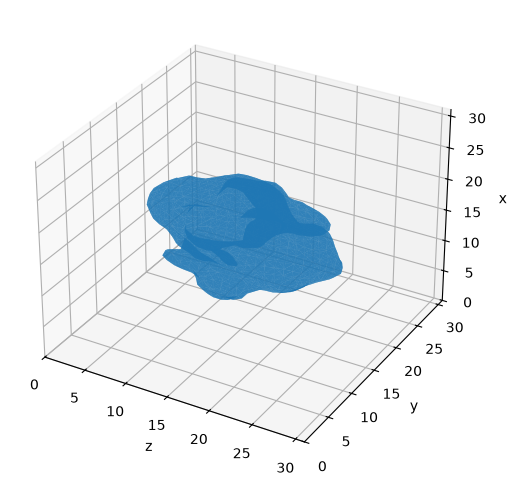

In [94]:
mean_rib_vol = np.mean([volume for _, volume in coh_list], axis=0)

v = napari.Viewer(ndisplay=3)
v.add_image(
    mean_rib_vol,
    name="mean ribosome",
    rendering="iso",
    iso_threshold=float(np.percentile(mean_rib_vol, 95)),
)
v.add_image(
    cohesin_small,
    name="gt ribosom",
)

threshold = np.percentile(mean_rib_vol, 95)
verts, faces, _, _ = marching_cubes(mean_rib_vol, level=threshold)
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
ax.add_collection3d(Poly3DCollection(verts[faces], alpha=0.7, edgecolor="none"))
ax.set(
    xlim=(0, mean_rib_vol.shape[0]),
    ylim=(0, mean_rib_vol.shape[1]),
    zlim=(0, mean_rib_vol.shape[2]),
    xlabel="z",
    ylabel="y",
    zlabel="x",
)
plt.show()

## Extract ground truth proteins

In [96]:
# no_noise_tomograms

rib_list_no_noise = []

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "cohesin":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = no_noise_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 26
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        rib_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + rib_vol.shape[0],
            y_start:y_start + rib_vol.shape[1],
            x_start:x_start + rib_vol.shape[2],
        ]

        rib_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        rib_vol_unrot = unrotate(
            rib_vol,
            parse_rot(line["rotation"]),
            center_offset_zyx=rib_center_offset_zyx,
        )

        rib_list_no_noise.append((i, rib_vol))

coh_list_no_noise = []
coh_center_offset_zyx = ground_truth_center_offset_zyx(cohesin)

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "ribosome":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = no_noise_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 15
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        coh_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + coh_vol.shape[0],
            y_start:y_start + coh_vol.shape[1],
            x_start:x_start + coh_vol.shape[2],
        ]

        coh_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        coh_vol_unrot = unrotate(
            coh_vol,
            parse_rot(line["rotation"]),
            center_offset_zyx=coh_center_offset_zyx
        )

        coh_list_no_noise.append((i, coh_vol))

ribosome 115 66 50
ribosome 38 210 35
ribosome 126 224 71
ribosome 142 187 73
ribosome 40 63 55
ribosome 158 37 72
ribosome 91 40 72
ribosome 228 34 46
ribosome 227 83 34
ribosome 82 208 58
ribosome 33 184 56
ribosome 54 155 53
ribosome 174 225 68
ribosome 110 157 30
ribosome 171 108 33
ribosome 136 130 44
ribosome 172 64 44
ribosome 93 125 70
ribosome 196 184 60
ribosome 74 85 26
ribosome 199 76 31
ribosome 155 165 35
ribosome 176 146 46
ribosome 142 108 31
ribosome 170 158 45
ribosome 110 177 72
ribosome 68 124 55
ribosome 86 47 32
ribosome 100 152 38
ribosome 208 205 59
ribosome 62 35 63
ribosome 114 78 65
ribosome 193 114 52
ribosome 171 229 33
ribosome 222 146 51
ribosome 135 136 55
ribosome 34 135 42
ribosome 215 63 38
ribosome 167 131 35
ribosome 81 166 55
ribosome 36 209 37
ribosome 86 107 57
ribosome 154 107 70
ribosome 208 90 50
ribosome 107 163 70
ribosome 41 107 50
ribosome 139 96 35
ribosome 63 92 52
ribosome 96 38 26
ribosome 60 57 64
ribosome 96 93 45
ribosome 80 205 70


## Compare the proteins

In [129]:
from torch_fourier_slice.slice_extraction._extract_central_slices_rfft_3d import (
    extract_central_slices_rfft_3d,
)
from torch_ctf import calculate_ctf_2d
from torch_grid_utils import fftfreq_grid



def rotation_matrix_y(angle_deg, device="cpu"):
    theta = torch.deg2rad(torch.tensor(float(angle_deg), device=device))
    c, s = torch.cos(theta), torch.sin(theta)
    return torch.stack([
        torch.stack([ c, torch.tensor(0.0, device=device),  s]),
        torch.stack([ torch.tensor(0.0, device=device), torch.tensor(1.0, device=device), torch.tensor(0.0, device=device)]),
        torch.stack([-s, torch.tensor(0.0, device=device),  c]),
    ])

def extract_slices(volume, angles):
    """
    Extract slices from a 3D volume at specified angles.

    Parameters
    ----------
    volume : torch.Tensor
        The 3D volume from which to extract slices.
    angles : list
        A list of angles (in degrees) at which to extract slices.

    Returns
    -------
    torch.Tensor
        A tensor containing the extracted slices.
    """

    rotation_matrices = torch.stack([rotation_matrix_y(a) for a in angles])

    return extract_central_slices_rfft_3d(volume, rotation_matrices)

In [152]:

# need to add minus sign for correct CTF, weird...
VOLTAGE = 300

ctf_values = {
    "defocus": 3,  # in micrometers
    "astigmatism": 0.0,  # in micrometers
    "astigmatism_angle": 0.0,  # in degrees
    "voltage": VOLTAGE,  # in volts
    "spherical_aberration": 2.7, # mm float | torch.Tensor,
    "amplitude_contrast": 0.07, # float | torch.Tensor,
    "phase_shift": 0.0, # float | torch.Tensor,
    "pixel_size": PIXEL_SPACING, # float | torch.Tensor,
    # "image_shape": (BOX, BOX), # tuple[int, int],
    "rfft": True, # bool,
    "fftshift": False, # bool,
    "beam_tilt_mrad": None, # torch.Tensor | None = None,
    "even_zernike_coeffs": None, # dict | None = None,
    "odd_zernike_coeffs": None, # dict | None = None,
    "transform_matrix": None, # torch.Tensor | None = None,
    "return_complex_ctf": False, # bool = False, 
}

d_rib = r_rib*2
ctf_image_rib = - calculate_ctf_2d(**ctf_values, image_shape=(d_rib, d_rib))
frequency_grid = fftfreq_grid(image_shape=(d_rib, d_rib), rfft=True, fftshift=False, norm=True)
ctf_image_rib[frequency_grid > 0.5] = 0

print(np.shape(ctf_image_rib))

d_coh = r_coh*2
ctf_image_coh = - calculate_ctf_2d(**ctf_values, image_shape=(d_coh, d_coh))
frequency_grid = fftfreq_grid(image_shape=(d_coh, d_coh), rfft=True, fftshift=False, norm=True)
ctf_image_coh[frequency_grid > 0.5] = 0

print(np.shape(ctf_image_coh))

torch.Size([52, 27])
torch.Size([30, 16])


In [153]:
def apply_ctf(slices, ctf_values, flip_sign=True):
    s = torch.as_tensor(slices, dtype=torch.float32)
    h, w = s.shape[-2:]
    ctf = calculate_ctf_2d(**{**ctf_values, "rfft": True, "fftshift": False}, image_shape=(h, w))
    if flip_sign:
        ctf = -ctf                                   # same sign convention as your cell
    ctf = ctf.to(s.device)
    return torch.fft.irfft2(torch.fft.rfft2(s) * ctf, s=(h, w))

In [ ]:
angles = np.arange(-90, 91, 1)
mean_values = {}

rib_ctf_values = {**ctf_values, "rfft": True, "fftshift": False}
rib_ctf_values.pop("image_shape", None)

for r in range(len(rib_list[:1])):
    rib_noise = torch.tensor(rib_list[r][1])
    rib_noise_slices = extract_slices(rib_noise, angles)

    rib_no_noise = torch.tensor(rib_list_no_noise[r][1])
    rib_no_noise_slices = extract_slices(rib_no_noise, angles)

    image_size = rib_no_noise.shape[-1]
    ctf = -calculate_ctf_2d(
        **rib_ctf_values,
        image_shape=(image_size, image_size),
    ).to(rib_no_noise_slices.device)
    rib_no_noise_ctf_slices = rib_no_noise_slices * ctf

    rib_noise_real_slices = torch.fft.irfft2(
        rib_noise_slices, s=(image_size, image_size)
    )
    rib_no_noise_ctf_real_slices = torch.fft.irfft2(
        rib_no_noise_ctf_slices, s=(image_size, image_size)
    )

    angle_index = int(np.where(angles == 0)[0][0])
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(rib_noise_real_slices[angle_index].cpu(), cmap="gray")
    axes[0].set_title("Noisy slice, 0 degrees")
    axes[1].imshow(rib_no_noise_ctf_real_slices[angle_index].cpu(), cmap="gray")
    axes[1].set_title("No-noise slice with CTF, 0 degrees")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()        tilt_series_ctf = torch.fft.irfftn(
            torch.fft.rfftn(tilt_series, dim=(-2, -1)) * ctf_per_tilt_subtomo,
            dim=(-2, -1),
            s=image_shape,
            )


TypeError: torch_ctf.ctf_2d.calculate_ctf_2d() got multiple values for keyword argument 'image_shape'